# Bonus B3: How to build a typed desk agent with Pydantic AI

## Goal

We build a Chinook support-desk agent that returns a Python object, receives its database through injected dependencies, and checks proposed answers in code. The moment is a refund recommendation that has the right field types but violates a small teaching policy. An output validator rejects it, and the message history shows the correction sent back to the model.

## What you will learn

- How to describe an expected answer with a Pydantic model, and why a valid field is not a true fact.
- How to construct a Pydantic AI agent directly and pass services through `RunContext`.
- How to read the three-tool desk run: its messages, typed result, requests, tokens and price.
- How to enforce a policy with an output validator and find its `ModelRetry` in the message history.
- How to test tools and repairs with `FunctionModel` while live model requests are disabled.
- When Pydantic AI is worth choosing over the typed answers of labs 07 and 10.

This notebook stands alone. It reads the public Chinook sample database; the refund case is invented. We use a single agent because the question needs three small lookups, with no reason to divide the work among specialists.

## Setup

The first cell finds the repository, loads the configured model and prices, and takes the key from `.env` without printing it. Use the repository's environment, as explained in [Lab 00](../../00_Environment_Check/README.md).

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


## Part A: Describe the answer as a Python object

A support application needs separate fields for invoice count, total and rep. A sentence is convenient for a person; named fields are easier for code to check. Start with the answer we want, before declaring its schema. Customer 6 in the sample is Helena Holý.

In [2]:
expected = {"customer_id": 6, "invoice_count": 7, "total": 49.62, "support_rep": "Steve Johnson"}
print(expected)
print("invoice count:", expected["invoice_count"])
print("rep:", expected["support_rep"])

{'customer_id': 6, 'invoice_count': 7, 'total': 49.62, 'support_rep': 'Steve Johnson'}
invoice count: 7
rep: Steve Johnson


A dictionary maps a field name to its value. `expected["invoice_count"]` reads one value by name. The total is in US dollars, summed across invoices, rather than the value of one invoice.

A [Pydantic model](https://docs.pydantic.dev/latest/concepts/models/) describes the fields we accept. `int` means whole number, `float` means a numeric amount, and `str` means text. `Field(ge=0)` requires a value greater than or equal to zero. We use those constraints where a negative number would have no meaning in this answer.

In [3]:
from pydantic import BaseModel, Field, ValidationError

class DeskAnswer(BaseModel):
    customer_id: int = Field(gt=0)
    invoice_count: int = Field(ge=0)
    total: float = Field(ge=0)
    support_rep: str

answer = DeskAnswer.model_validate(expected)
print(type(answer).__name__)
print(answer.invoice_count, answer.support_rep)
print(answer.model_dump())

DeskAnswer
7 Steve Johnson
{'customer_id': 6, 'invoice_count': 7, 'total': 49.62, 'support_rep': 'Steve Johnson'}


`model_validate()` checks the dictionary and returns a `DeskAnswer`. We read its fields with dots; `model_dump()` converts it back to a dictionary. Now change the count to text that cannot represent a number. We catch the validation error so the rest of the notebook can continue.

In [4]:
try:
    DeskAnswer.model_validate({**expected, "invoice_count": "many"})
except ValidationError as error:
    print("field rejected:", error.errors()[0]["loc"], error.errors()[0]["type"])

wrong = DeskAnswer.model_validate({**expected, "invoice_count": 99})
print("well-typed but unverified:", wrong.model_dump())

field rejected: ('invoice_count',) int_parsing
well-typed but unverified: {'customer_id': 6, 'invoice_count': 99, 'total': 49.62, 'support_rep': 'Steve Johnson'}


The schema rejects `"many"` because it cannot be parsed as an integer. It accepts 99: a non-negative integer fits the field, even though Helena has 7 invoices. `**expected` copies the dictionary's fields into a new dictionary; the later `invoice_count` entry replaces that one value. The original is unchanged.

**Checkpoint A.** You have a `DeskAnswer`, an `int_parsing` error for `invoice_count`, and an accepted object with count 99. A schema establishes the shape and declared constraints. We need a trusted lookup to establish the facts.

## Part B: Pass the database through dependencies

An agent needs access to the shop, but its database connection should be chosen by our application. **Dependency injection** means we pass the service a run needs, rather than opening it inside every tool or asking the model to choose it. A dependency is available to our code; passing it does not automatically copy its contents into a prompt.

Open the bundled database read-only. `mode=ro` makes SQLite refuse writes, and `check_same_thread=False` allows the framework to call synchronous tools on a worker thread.

In [5]:
import sqlite3

DB_PATH = ROOT / "data" / "chinook.db"
connection = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True, check_same_thread=False)
print(connection.execute("SELECT CustomerId, FirstName, LastName FROM customers WHERE CustomerId = 6").fetchone())

(6, 'Helena', 'Holý')


The row identifies the customer before any model gets involved. Put the connection and an application-side tool log in one dependency object. `@dataclass` supplies a constructor from the annotated fields. `field(default_factory=list)` creates a different empty list for every run, so one run's tool history cannot become another's.

In [6]:
from dataclasses import dataclass, field

@dataclass
class DeskDeps:
    connection: sqlite3.Connection
    calls: list[dict] = field(default_factory=list)

deps = DeskDeps(connection)
print("dependency fields:", list(DeskDeps.__annotations__))
print("calls before a tool:", deps.calls)

dependency fields: ['connection', 'calls']
calls before a tool: []


Pydantic AI supplies a [`RunContext`](https://pydantic.dev/docs/ai/core-concepts/dependencies/) to each tool. `ctx.deps` is the object passed to `run(deps=...)`; the model supplies only the remaining arguments. These are the same three named lookups used for the desk baseline: find the customer, get invoice totals, get the rep.

The SQL text is fixed, and `?` passes a value as a parameter rather than building SQL from model text. Each result repeats `customer_id`, so we can trace which customer it describes.

In [7]:
from pydantic_ai import RunContext

def find_customer(ctx: RunContext[DeskDeps], name: str) -> list[dict]:
    """Find a shop customer by exact full name and return matching customer IDs."""
    ctx.deps.calls.append({"tool": "find_customer", "name": name})
    rows = ctx.deps.connection.execute(
        "SELECT CustomerId, FirstName || ' ' || LastName, Country FROM customers "
        "WHERE FirstName || ' ' || LastName = ?", (name,)).fetchall()
    matches = [{"customer_id": row[0], "name": row[1], "country": row[2]} for row in rows]
    ctx.deps.calls[-1]["matched_ids"] = [match["customer_id"] for match in matches]
    return matches

def get_invoices(ctx: RunContext[DeskDeps], customer_id: int) -> dict:
    """Count a customer's invoices and add up their total in US dollars."""
    ctx.deps.calls.append({"tool": "get_invoices", "customer_id": customer_id})
    count, total = ctx.deps.connection.execute(
        "SELECT COUNT(*), ROUND(SUM(Total), 2) FROM invoices WHERE CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "invoice_count": count, "total": total}

def get_support_rep(ctx: RunContext[DeskDeps], customer_id: int) -> dict:
    """Name the support rep who looks after a customer."""
    ctx.deps.calls.append({"tool": "get_support_rep", "customer_id": customer_id})
    row = ctx.deps.connection.execute(
        "SELECT e.FirstName || ' ' || e.LastName FROM customers c "
        "JOIN employees e ON e.EmployeeId = c.SupportRepId WHERE c.CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "support_rep": row[0] if row else None}

Before a model chooses these calls, call them ourselves. A context also holds the model and usage ledger; the framework usually constructs it. Here we construct one directly to see where the connection enters the function.

[`OpenAIProvider`](https://pydantic.dev/docs/ai/models/openai/) takes the configured key from the environment. `OpenAIResponsesModel` selects Responses explicitly. We only add the reasoning setting when `EFFORT` has a value, so models with no reasoning setting can omit it.

In [8]:
from pydantic_ai.models.openai import OpenAIResponsesModel, OpenAIResponsesModelSettings
from pydantic_ai.providers.openai import OpenAIProvider
from pydantic_ai.usage import RunUsage

provider = OpenAIProvider()
model = OpenAIResponsesModel(MODEL, provider=provider)
model_settings = OpenAIResponsesModelSettings(max_tokens=500)
if EFFORT:
    model_settings["openai_reasoning_effort"] = EFFORT
context = RunContext(deps=deps, model=model, usage=RunUsage())
print(type(model).__name__, model_settings)
print(find_customer(context, "Helena Holý"))
print(get_invoices(context, 6))
print(get_support_rep(context, 6))

OpenAIResponsesModel {'max_tokens': 500, 'openai_reasoning_effort': 'none'}
[{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]
{'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
{'customer_id': 6, 'support_rep': 'Steve Johnson'}


The context reaches each function, but the results contain only the selected fields. The whole connection is never returned to the model. A type annotation helps editors and type checkers describe dependencies. The fixed SQL restricts each tool's operation, and the read-only connection prevents writes. Customer-level access control would be a separate application rule.

**Checkpoint B.** The direct calls return customer 6, 7 invoices totaling $49.62, and Steve Johnson. `calls` records the three functions our code actually executed. We can now give the same functions to an agent.

## Part C: Run and measure the typed desk agent

We have used the model/provider objects and the tools directly. Now construct the public `Agent`, register the functions, and make one run. `deps_type` describes what our tools receive; `output_type` describes the final answer. Registering `ctx` tools with `.tool()` tells the framework to inject that first argument.

The instructions require evidence from all three lookups. This matters with a public sample database: a model may remember the answer, and a correct answer alone would not demonstrate a lookup.

In [9]:
from pydantic_ai import Agent, UsageLimits

desk = Agent(
    model,
    name="Chinook desk",
    deps_type=DeskDeps,
    output_type=DeskAnswer,
    instructions=("Answer customer questions using the three lookup tools. First find the customer, "
                  "then get invoices and the support rep. Return only facts from the tool results."),
    model_settings=model_settings,
    retries=2,
)
desk.tool(find_customer)
desk.tool(get_invoices)
desk.tool(get_support_rep)
print(type(desk).__name__, "| output:", DeskAnswer.__name__)

Agent | output: DeskAnswer


`await desk.run(...)` runs the loop: ask the model, execute its requested tools, return the results, and stop at a valid output. `await` lets the notebook wait for this asynchronous operation. Each call starts a new conversation unless message history is supplied.

The request cap bounds model turns and the tool cap bounds successful application tool calls. Token limits are checked during execution; a request already in flight can exceed a total-token limit. This is an application guard, with provider spend controls still needed for a shared budget.

⚠️ The following live cells call the configured OpenAI model and incur token charges. The deterministic tests later replace that model.

In [10]:
import time

QUESTION = "How many invoices does Helena Holý have, what do they add up to, and who is her support rep?"
baseline_deps = DeskDeps(connection)
started = time.perf_counter()
baseline = await desk.run(
    QUESTION, deps=baseline_deps,
    usage_limits=UsageLimits(request_limit=6, tool_calls_limit=3, total_tokens_limit=8000),
)
baseline_seconds = time.perf_counter() - started
print(type(baseline).__name__, type(baseline.output).__name__)
print(baseline.output.model_dump())
print("executed tools:", baseline_deps.calls)

AgentRunResult DeskAnswer
{'customer_id': 6, 'invoice_count': 7, 'total': 49.62, 'support_rep': 'Steve Johnson'}
executed tools: [{'tool': 'find_customer', 'name': 'Helena Holý', 'matched_ids': [6]}, {'tool': 'get_invoices', 'customer_id': 6}, {'tool': 'get_support_rep', 'customer_id': 6}]


The result contains a `DeskAnswer`, so callers can read fields without parsing prose. The application log shows executed business functions; now inspect the framework's actual protocol. A `ToolCallPart` is a request to call a function. A `ToolReturnPart` contains its result. Typed output uses an output tool named `final_result` by default; it transports the answer and does not execute a shop action.

In [11]:
from pydantic_ai.messages import ModelResponse, ToolCallPart, ToolReturnPart

for index, message in enumerate(baseline.all_messages(), start=1):
    print(index, type(message).__name__, [type(part).__name__ for part in message.parts])
    for part in message.parts:
        if isinstance(part, ToolCallPart):
            print("  proposed:", part.tool_name, part.args)
        elif isinstance(part, ToolReturnPart):
            print("  returned:", part.tool_name, part.content)

1 ModelRequest ['UserPromptPart']
2 ModelResponse ['ToolCallPart']
  proposed: find_customer {"name":"Helena Holý"}
3 ModelRequest ['ToolReturnPart']
  returned: find_customer [{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]
4 ModelResponse ['ToolCallPart', 'ToolCallPart']
  proposed: get_invoices {"customer_id":6}
  proposed: get_support_rep {"customer_id":6}
5 ModelRequest ['ToolReturnPart', 'ToolReturnPart']
  returned: get_invoices {'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
  returned: get_support_rep {'customer_id': 6, 'support_rep': 'Steve Johnson'}
6 ModelResponse ['ToolCallPart']
  proposed: final_result {"customer_id":6,"invoice_count":7,"total":49.62,"support_rep":"Steve Johnson"}
7 ModelRequest ['ToolReturnPart']
  returned: final_result Final result processed.


Each `ModelResponse` is one model reply, with that request's usage. `baseline.usage` adds up the whole run. We price ordinary input, cached reads, cache writes and output separately from `models.env`. Input tokens already include cached tokens, so subtract them before pricing ordinary input.

The cell then gathers the run's numbers into one dictionary, `baseline_measurement`: requests, tokens, price, time, the tool path and whether the answer matches `expected`. It adds no new idea; it puts everything we measured in one printed record. The same fields from the learner run and the solution run are kept in `resources/baseline_measurement.json`, so the two can be compared without running either. Read `requests`, `input_tokens`, `output_tokens` and `cost_usd` first; the two assertions at the end are the checks.

In [12]:
import json

usage = baseline.usage
print("per-request usage:")
for message in baseline.all_messages():
    if isinstance(message, ModelResponse):
        print(message.usage)
ordinary_input = usage.input_tokens - usage.cache_read_tokens - usage.cache_write_tokens
baseline_cost = (
    ordinary_input * float(settings["PRICE_INPUT_PER_MILLION"])
    + usage.cache_read_tokens * float(settings["PRICE_CACHED_INPUT_PER_MILLION"])
    + usage.cache_write_tokens * float(settings["PRICE_CACHE_WRITE_PER_MILLION"])
    + usage.output_tokens * float(settings["PRICE_OUTPUT_PER_MILLION"])
) / 1_000_000
facts_correct = baseline.output.model_dump() == expected
baseline_measurement = {
    "question": QUESTION, "requests": usage.requests,
    "input_tokens": usage.input_tokens, "cached_input_tokens": usage.cache_read_tokens,
    "cache_write_tokens": usage.cache_write_tokens, "output_tokens": usage.output_tokens,
    "cost_usd": baseline_cost, "seconds": round(baseline_seconds, 3),
    "tool_path": [call["tool"] for call in baseline_deps.calls],
    "answer": baseline.output.model_dump(), "facts_correct": facts_correct,
}
print(json.dumps(baseline_measurement, indent=2, ensure_ascii=False))
assert facts_correct
assert {call["tool"] for call in baseline_deps.calls} == {"find_customer", "get_invoices", "get_support_rep"}
print("✅ Baseline facts and three executed tools checked")

per-request usage:
RequestUsage(cost=Decimal('0.0000326'), details={'reasoning_tokens': 0}, input_tokens=221, output_tokens=21)
RequestUsage(cost=Decimal('0.0000534'), details={'reasoning_tokens': 0}, input_tokens=274, output_tokens=52)
RequestUsage(cost=Decimal('0.0000557'), details={'reasoning_tokens': 0}, input_tokens=377, output_tokens=36)
{
  "question": "How many invoices does Helena Holý have, what do they add up to, and who is her support rep?",
  "requests": 3,
  "input_tokens": 872,
  "cached_input_tokens": 0,
  "cache_write_tokens": 0,
  "output_tokens": 109,
  "cost_usd": 0.0001417,
  "seconds": 8.036,
  "tool_path": [
    "find_customer",
    "get_invoices",
    "get_support_rep"
  ],
  "answer": {
    "customer_id": 6,
    "invoice_count": 7,
    "total": 49.62,
    "support_rep": "Steve Johnson"
  },
  "facts_correct": true
}
✅ Baseline facts and three executed tools checked


The saved baseline made 3 model requests, with 872 input and 109 output tokens; its token price was $0.0001417. The count includes the final typed answer. Tools may share a model turn, so three business functions need not mean three tool-request turns.

Pydantic AI supplies argument schemas, tool dispatch, output parsing, usage and retries. We still choose the tools and compare the facts. This run's matching fields establish correctness for this question, rather than general reliability.

**Checkpoint C.** `facts_correct` is true, all three business tools executed, and the typed result agrees with Part B. Look at the ordered message list to explain how the model obtained each field.

## Part D: Reject a typed decision that violates a policy

A boolean field cannot express every business rule. Use a tiny, invented refund policy to see the difference: amounts above $10 may only be drafted for human review. This is a teaching fixture, separate from the bundled shop policies; no money is moved.

First show an ordinary proposed decision and the application's policy. We intentionally leave that rule out of the agent's instructions on the first run, so the validator has something it may need to correct.

In [13]:
policy = {"automatic_refund_limit": 10.0, "requested_amount": 12.0}
proposal = {"amount": 12.0, "action": "approve", "requires_human": False}
print("teaching policy:", policy)
print("proposal:", proposal)

teaching policy: {'automatic_refund_limit': 10.0, 'requested_amount': 12.0}
proposal: {'amount': 12.0, 'action': 'approve', 'requires_human': False}


The amount is numeric, `action` must be one of two words, and `requires_human` is a boolean. The proposal fits all those types. `Literal` lists the allowed words. The dependency object holds the requested amount and the review threshold; it also records every output the validator receives.

In [14]:
from typing import Literal

class RefundDecision(BaseModel):
    amount: float
    action: Literal["approve", "draft"]
    requires_human: bool

@dataclass
class RefundDeps:
    automatic_refund_limit: float = 10.0
    requested_amount: float = 12.0
    attempts: list[dict] = field(default_factory=list)

invalid_decision = RefundDecision.model_validate(proposal)
print("Pydantic accepted:", invalid_decision.model_dump())

Pydantic accepted: {'amount': 12.0, 'action': 'approve', 'requires_human': False}


Use a small ordinary function for the policy check, then register a validator that uses it. Returning `None` means this proposal passes the rules we wrote; returning a sentence explains what must change. The amount check prevents a model from satisfying the threshold by silently reducing the requested refund.

An [output validator](https://pydantic.dev/docs/ai/core-concepts/output/#output-validators) runs after parsing. Raising `ModelRetry` rejects the candidate and adds a `ToolReturnPart` marked `outcome="retried"` to the conversation, within the configured retry limit. The retry result carries the output tool call ID and correction text. Its `retry` metadata records the cause and attempt. It does not itself correct the object or guarantee that a model can repair it. Older examples use `RetryPromptPart`; current [retry documentation](https://pydantic.dev/docs/ai/core-concepts/retries/) marks that combined type deprecated.

In [15]:
def policy_problem(deps: RefundDeps, decision: RefundDecision) -> str | None:
    if decision.amount != deps.requested_amount:
        return f"Keep the requested amount ${deps.requested_amount:.2f}."
    if decision.amount > deps.automatic_refund_limit and (decision.action != "draft" or not decision.requires_human):
        return f"For amounts over ${deps.automatic_refund_limit:.2f}, action must be draft and requires_human must be true."
    return None

print("policy rejects:", policy_problem(RefundDeps(), invalid_decision))
print("corrected passes:", policy_problem(RefundDeps(), RefundDecision(amount=12, action="draft", requires_human=True)))

policy rejects: For amounts over $10.00, action must be draft and requires_human must be true.
corrected passes: None


The hand-made proposal is rejected even though its fields parse. Now let the same check control a real agent run. The instructions below ask for the requested action but omit the threshold; dependency injection alone does not tell the model about it. The decorator registers `validate_refund` as an output validator for this agent.

In [16]:
from pydantic_ai import ModelRetry

refund_agent = Agent(
    model, name="Refund recommendation", deps_type=RefundDeps, output_type=RefundDecision,
    instructions="Recommend the requested refund action. Do not issue any payment.",
    model_settings=model_settings, retries=2,
)

@refund_agent.output_validator
def validate_refund(ctx: RunContext[RefundDeps], decision: RefundDecision) -> RefundDecision:
    ctx.deps.attempts.append(decision.model_dump())
    problem = policy_problem(ctx.deps, decision)
    if problem:
        raise ModelRetry(problem)
    return decision

Predict the first proposal: will the model know an application's unmentioned $10 rule? We keep every candidate and every retry message, rather than inferring repair from a correct final answer.

In [17]:
refund_prompt = "Recommend automatic approval of a $12 refund for an invented teaching case."
refund_deps = RefundDeps()
refund_result = await refund_agent.run(
    refund_prompt, deps=refund_deps,
    usage_limits=UsageLimits(request_limit=4, total_tokens_limit=4000),
)
print("validator candidates:")
for attempt in refund_deps.attempts:
    print(attempt)
for message in refund_result.all_messages():
    for part in message.parts:
        if isinstance(part, ToolReturnPart) and part.outcome == "retried":
            print(type(part).__name__, "|", part.tool_name, "|", part.outcome, "|", part.content, "|", part.retry)
print("accepted:", refund_result.output.model_dump())
print("model requests:", refund_result.usage.requests)
assert policy_problem(refund_deps, refund_result.output) is None

validator candidates:
{'amount': 12.0, 'action': 'approve', 'requires_human': False}
{'amount': 12.0, 'action': 'draft', 'requires_human': True}
ToolReturnPart | final_result | retried | For amounts over $10.00, action must be draft and requires_human must be true. | RetryInfo(cause='model_retry', attempt=1, max_retries=2)
accepted: {'amount': 12.0, 'action': 'draft', 'requires_human': True}
model requests: 2


The single saved run proposed approval first, received one correction, and returned a draft for human review. We repeat the unchanged question to see whether that first rejection is consistent. The following small helper only collects the message parts just inspected; it does not hide agent construction or execution. The helper visits each message, then each part, and keeps only retried tool returns.

In [18]:
def retry_parts(result):
    return [part for message in result.all_messages() for part in message.parts
            if isinstance(part, ToolReturnPart) and part.outcome == "retried"]

print("retry messages in the run:", len(retry_parts(refund_result)))

retry messages in the run: 1


One retried part, the single correction we printed above. Now we run the same question five more times, each with a fresh `RefundDeps`, and print every candidate the validator saw, the number of retries and the model requests.

In [19]:
repair_runs = []
for trial in range(5):
    trial_deps = RefundDeps()
    result = await refund_agent.run(refund_prompt, deps=trial_deps,
                                   usage_limits=UsageLimits(request_limit=4, total_tokens_limit=4000))
    repair_runs.append((result, trial_deps))
    print("trial", trial + 1, "| candidates:", trial_deps.attempts,
          "| retries:", len(retry_parts(result)), "| requests:", result.usage.requests)
print("runs with an output retry:", sum(bool(retry_parts(result)) for result, _ in repair_runs), "of", len(repair_runs))

trial 1 | candidates: [{'amount': 12.0, 'action': 'approve', 'requires_human': False}, {'amount': 12.0, 'action': 'draft', 'requires_human': True}] | retries: 1 | requests: 2


trial 2 | candidates: [{'amount': 12.0, 'action': 'approve', 'requires_human': False}, {'amount': 12.0, 'action': 'draft', 'requires_human': True}] | retries: 1 | requests: 2


trial 3 | candidates: [{'amount': 12.0, 'action': 'approve', 'requires_human': False}, {'amount': 12.0, 'action': 'draft', 'requires_human': True}] | retries: 1 | requests: 2


trial 4 | candidates: [{'amount': 12.0, 'action': 'approve', 'requires_human': False}, {'amount': 12.0, 'action': 'draft', 'requires_human': True}] | retries: 1 | requests: 2


trial 5 | candidates: [{'amount': 12.0, 'action': 'approve', 'requires_human': False}, {'amount': 12.0, 'action': 'draft', 'requires_human': True}] | retries: 1 | requests: 2
runs with an output retry: 5 of 5


The saved repeats had an output retry in 5 of 5 runs. Each printed candidate lets us read the failed proposal as well as the accepted one. If a future run starts with a valid draft, it needs no repair; the deterministic test in Part E still exercises the rejection path.

**Checkpoint D.** The hand-made `approve` proposal fails the rule. Every accepted live decision passes `policy_problem`. Locate the `ToolReturnPart` with `outcome="retried"` where a rejection occurred, and explain which field values it asked the model to change.

**In production:** include the rule in the instructions as useful context, and keep the deterministic check. Only the accepted object should reach a separate authorized action handler. Retries make more calls; they do not authorize a payment.

## Part E: Test the boundary without calling a model

Live runs show what a model did. Tests also need a predictable failure, even when a future model guesses the right policy immediately. [`FunctionModel`](https://pydantic.dev/docs/ai/guides/testing/) replaces a model with a Python function that returns model-message objects. The agent still runs its usual parsing and validators.

First write a model double for the refund path. It returns the invalid hand-made proposal until it sees a retry, then returns a valid draft. `info.output_tools[0].name` obtains the output transport's actual name rather than assuming one. `any(...)` becomes true as soon as one part matches the retry condition. The two choices in the returned dictionary change together: a retry switches the action to `draft` and human review to `True`.

In [20]:
from pydantic_ai.models.function import FunctionModel, AgentInfo
from pydantic_ai import models

def scripted_refund(messages, info: AgentInfo) -> ModelResponse:
    had_retry = any(isinstance(part, ToolReturnPart) and part.outcome == "retried" for message in messages for part in message.parts)
    candidate = {"amount": 12.0, "action": "draft" if had_retry else "approve", "requires_human": had_retry}
    return ModelResponse(parts=[ToolCallPart(info.output_tools[0].name, candidate)])

print("double returns:", ModelResponse.__name__, "containing", ToolCallPart.__name__)

double returns: ModelResponse containing ToolCallPart


Set `ALLOW_MODEL_REQUESTS=False` around the test so an accidental use of the live provider fails instead of spending money. `override(model=...)` swaps this agent's model temporarily; `finally` restores the global setting even if an assertion fails. This is a no-model test of our application boundary, rather than an evaluation of model quality.

In [21]:
previous = models.ALLOW_MODEL_REQUESTS
models.ALLOW_MODEL_REQUESTS = False
try:
    test_deps = RefundDeps()
    with refund_agent.override(model=FunctionModel(scripted_refund)):
        test_result = await refund_agent.run(refund_prompt, deps=test_deps)
finally:
    models.ALLOW_MODEL_REQUESTS = previous

print("no-model candidates:", test_deps.attempts)
for part in retry_parts(test_result):
    print(type(part).__name__, part.outcome, part.content, part.retry)
assert len(test_deps.attempts) == 2
assert len(retry_parts(test_result)) == 1
assert test_result.output.action == "draft" and test_result.output.requires_human
print("✅ No-model repair checked; provider requests: 0")

no-model candidates: [{'amount': 12.0, 'action': 'approve', 'requires_human': False}, {'amount': 12.0, 'action': 'draft', 'requires_human': True}]
ToolReturnPart retried For amounts over $10.00, action must be draft and requires_human must be true. RetryInfo(cause='model_retry', attempt=1, max_retries=2)
✅ No-model repair checked; provider requests: 0


This test used the refund validator, but the desk also needs factual checks. Register one now. It reads the trusted connection directly instead of using the model's answer as its own evidence. The model's customer ID must have appeared in a successful `find_customer` result, and the other fields must agree with the database.

Part B recorded matched customer IDs in the application log, so this check can distinguish a guessed ID from an ID the lookup returned. The decorator adds a validator to the same desk agent from this point onwards; the earlier measured baseline had only schema validation.

In [22]:
@desk.output_validator
def validate_desk(ctx: RunContext[DeskDeps], output: DeskAnswer) -> DeskAnswer:
    looked_up_ids = [customer_id for call in ctx.deps.calls if call["tool"] == "find_customer"
                     for customer_id in call.get("matched_ids", [])]
    if output.customer_id not in looked_up_ids:
        raise ModelRetry("Use a customer ID returned by find_customer.")
    count, total = ctx.deps.connection.execute(
        "SELECT COUNT(*), ROUND(SUM(Total), 2) FROM invoices WHERE CustomerId=?", (output.customer_id,)).fetchone()
    rep = ctx.deps.connection.execute(
        "SELECT e.FirstName || ' ' || e.LastName FROM customers c JOIN employees e "
        "ON e.EmployeeId=c.SupportRepId WHERE c.CustomerId=?", (output.customer_id,)).fetchone()[0]
    if (output.invoice_count, output.total, output.support_rep) != (count, total, rep):
        raise ModelRetry(f"Use the trusted facts: invoice_count={count}, total={total}, support_rep={rep}.")
    return output

The factual validator checks a structured answer against the trusted record, including a source customer ID. For the no-model desk test, the double requests all three tools and then deliberately returns 99 invoices. After the retry it returns the right count. This tests dispatch, injected dependencies, shape parsing and factual repair together.

The double uses the results already returned by the real read-only tools. We choose its calls in Python, so success cannot tell us whether a live model would choose those calls. The `returned` dictionary indexes results by tool name. This double asks for each lookup once, so each name identifies one result.

In [23]:
def scripted_desk(messages, info: AgentInfo) -> ModelResponse:
    returned = {part.tool_name: part.content for message in messages for part in message.parts
                if isinstance(part, ToolReturnPart)}
    if "find_customer" not in returned:
        return ModelResponse(parts=[ToolCallPart("find_customer", {"name": "Helena Holý"})])
    customer_id = returned["find_customer"][0]["customer_id"]
    if "get_invoices" not in returned:
        return ModelResponse(parts=[ToolCallPart("get_invoices", {"customer_id": customer_id}),
                                    ToolCallPart("get_support_rep", {"customer_id": customer_id})])
    repaired = any(isinstance(part, ToolReturnPart) and part.outcome == "retried" for message in messages for part in message.parts)
    candidate = {**returned["get_invoices"], "support_rep": returned["get_support_rep"]["support_rep"]}
    if not repaired:
        candidate["invoice_count"] = 99
    return ModelResponse(parts=[ToolCallPart(info.output_tools[0].name, candidate)])

In [24]:
previous = models.ALLOW_MODEL_REQUESTS
models.ALLOW_MODEL_REQUESTS = False
try:
    desk_test_deps = DeskDeps(connection)
    with desk.override(model=FunctionModel(scripted_desk)):
        desk_test = await desk.run(QUESTION, deps=desk_test_deps)
finally:
    models.ALLOW_MODEL_REQUESTS = previous

print("tools executed:", desk_test_deps.calls)
for part in retry_parts(desk_test):
    print(type(part).__name__, part.outcome, part.content, part.retry)
print("accepted:", desk_test.output.model_dump())
assert desk_test.output.model_dump() == expected
assert len(retry_parts(desk_test)) == 1
assert len(desk_test_deps.calls) == 3
print("✅ No-model tools, injection and factual repair checked; provider requests: 0")

tools executed: [{'tool': 'find_customer', 'name': 'Helena Holý', 'matched_ids': [6]}, {'tool': 'get_invoices', 'customer_id': 6}, {'tool': 'get_support_rep', 'customer_id': 6}]
ToolReturnPart retried Use the trusted facts: invoice_count=7, total=49.62, support_rep=Steve Johnson. RetryInfo(cause='model_retry', attempt=1, max_retries=2)
accepted: {'customer_id': 6, 'invoice_count': 7, 'total': 49.62, 'support_rep': 'Steve Johnson'}
✅ No-model tools, injection and factual repair checked; provider requests: 0


The scripted count 99 crossed the type boundary in Part A but failed the factual validator here. The test ran real SQL on the read-only sample database and fake model responses. Both no-model tests exercised a real `ModelRetry` and produced one `ToolReturnPart` with `outcome="retried"`; neither contacted a provider. Function-model usage can contain simulated request/token counts, so it must not be priced as paid OpenAI traffic.

**Checkpoint E.** Each test has one visible retry. The desk test executes three business tools and returns the four expected fields. These are repeatable checks of our code and the selected fixture. Live model choice still needs the separate run and evaluation cases.

## Part F: Follow the boundaries through the loop

The two agents share a pattern: the model proposes, the framework parses, and our code checks what the application can accept. This picture locates the dependencies, tool results and repair path. Ink is model work; lime is application code.

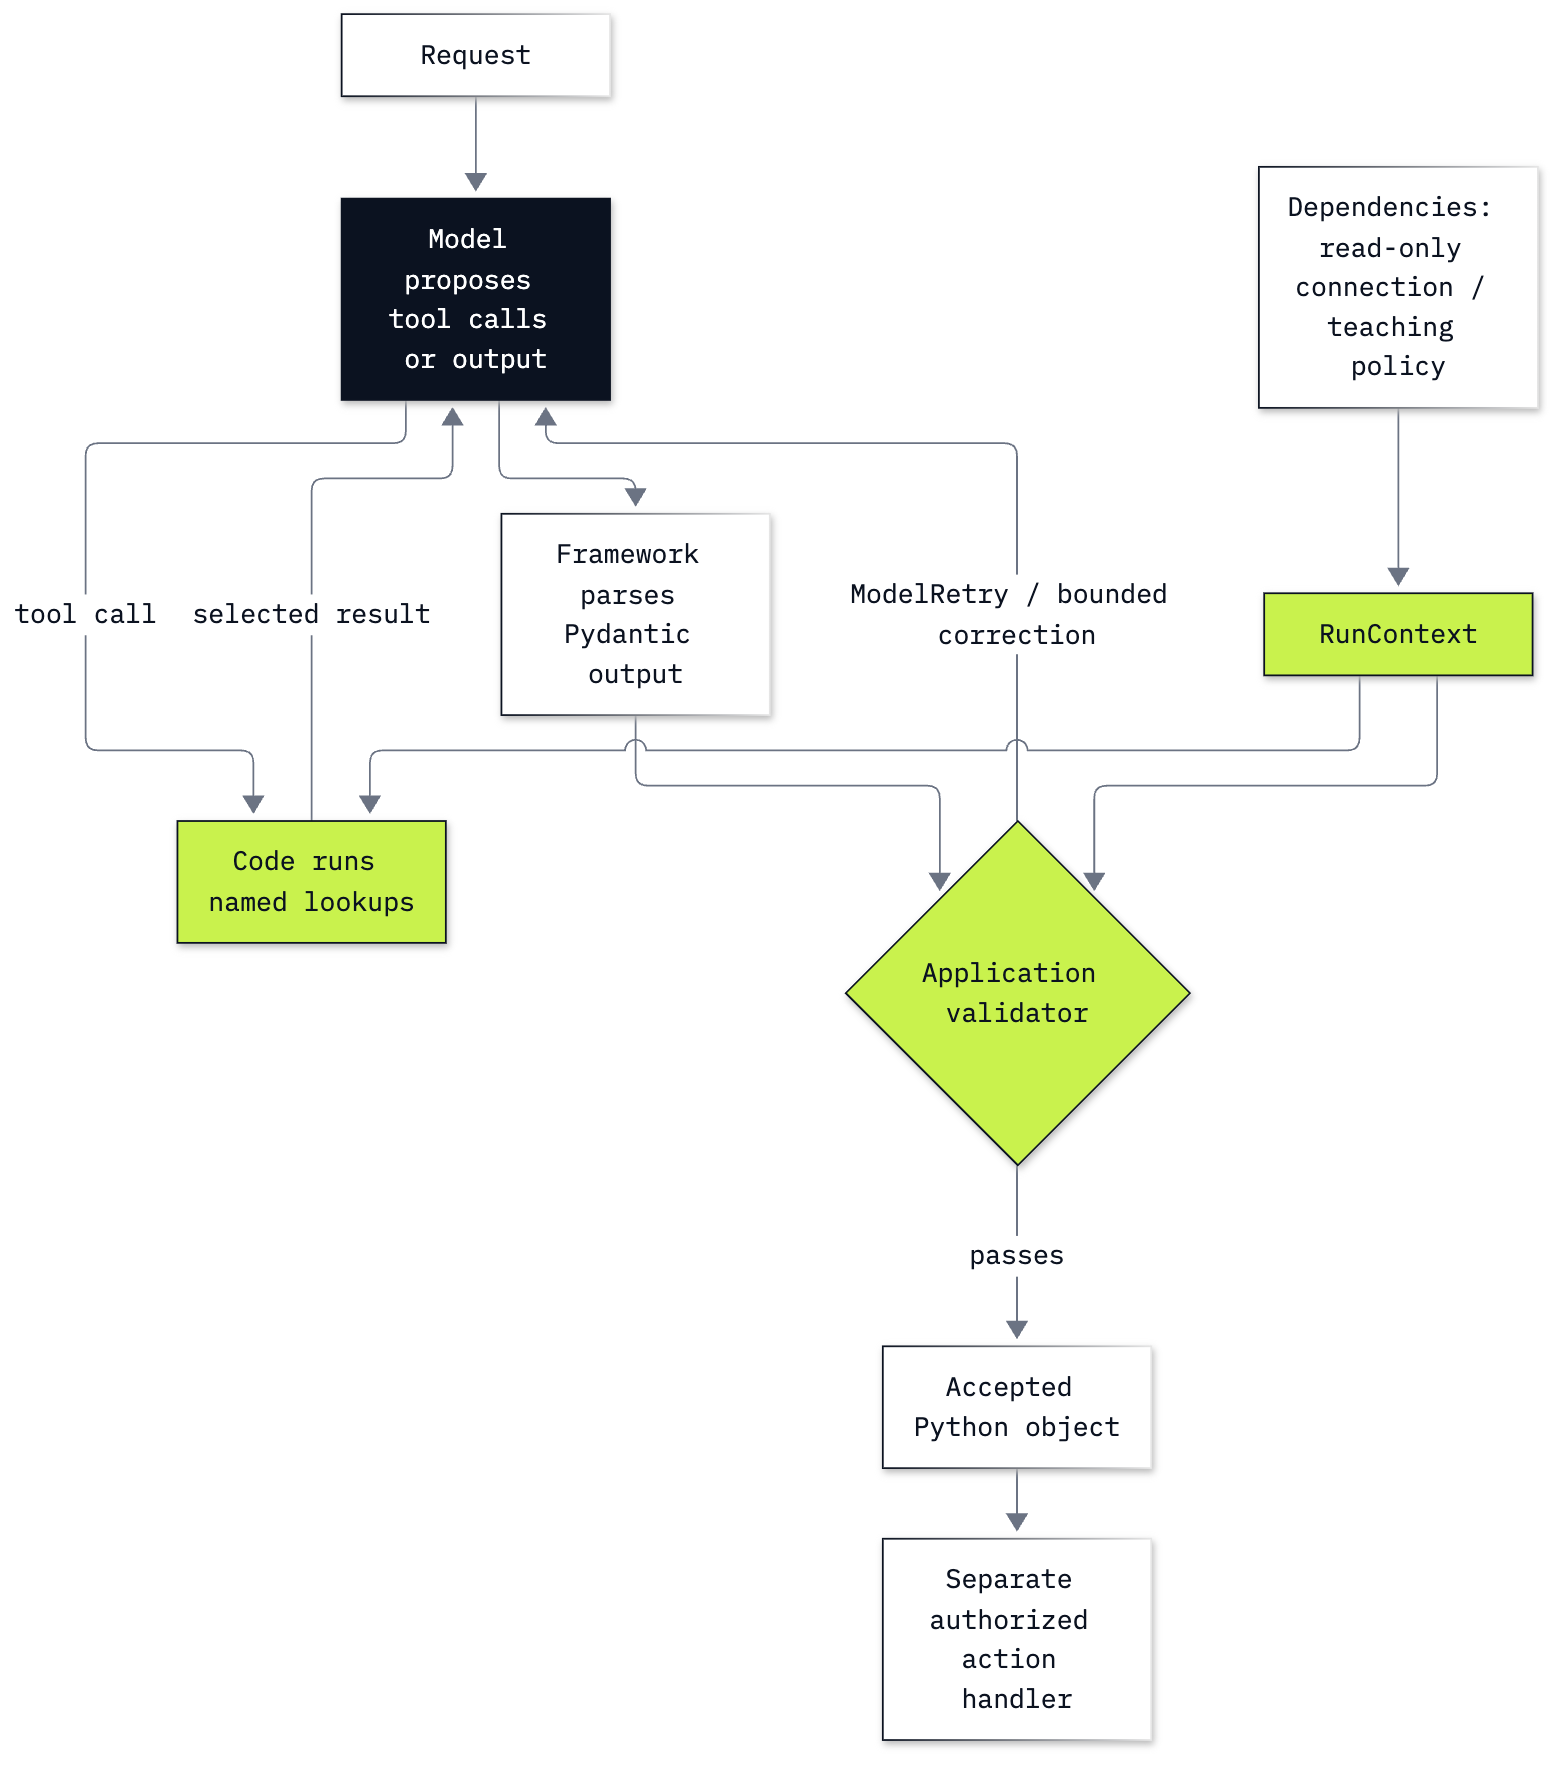

In [25]:
from IPython.display import Image, display

LAB = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "resources" / "labB3_typed_boundaries.png").exists())
display(Image(filename=str(LAB / "resources" / "labB3_typed_boundaries.png"), width=760))

Read the drawing from the request to the accepted object. Dependencies reach tools and validators through `RunContext`. Only what instructions or tools deliberately return becomes model-visible. A retry travels back as a message; it is another chance to propose an output, within a limit.

| Boundary | Pydantic AI supplies | Application still decides |
|---|---|---|
| Tool call | schema, argument parsing and dispatch | which operations and records a tool may access |
| Dependencies | `RunContext` injection | service lifecycle and which fields to expose |
| Output | parsing into a Python model | factual and business checks |
| Repair | retry message and attempt limit | correction rules and what happens on exhaustion |
| Tests | model override and message doubles | cases and expected outcomes |

**Checkpoint F.** Explain why the typed count 99 passed in Part A and was rejected in Part E. Then identify where the diagram would stop an invalid refund recommendation before an action handler.

## When to use it

The core path can already return a typed answer: lab 10's `create_agent` takes a `response_format`, and the Agents SDK takes an `output_type` (bonus B2 uses one). Pydantic AI earns its place when the checks around that answer are the point. Here the database reached every tool and validator through `RunContext` instead of a global, the output validator turned a well-typed but wrong refund decision into a draft for review (5 of 5 repeats, one retry each), and two tests ran the real tools and validators with `FunctionModel` and 0 provider requests. The Helena baseline itself looked like the other frameworks: 3 requests, $0.0001417. Choose Pydantic AI when you want typed dependencies, validators in code and model-free unit tests around an agent; if all you need is a typed final answer, stay with lab 07's SDK or lab 10's LangChain agent. Either way, a repair is another model request: each repaired run here made 2 instead of 1.

## What you can do now

- Describe the desk answer's fields and distinguish schema validity from factual validity.
- Construct a Pydantic AI agent and inject its read-only database through `RunContext`.
- Read model/tool messages, the typed result and measured cost of a complete run.
- Register a deterministic validator and find its repair message.
- Replace model responses in tests while exercising real tools and validators.

## Challenge

Use `desk` to answer the same three questions about **Puja Srivastava**, with a fresh `DeskDeps(connection)` and explicit request/tool/token limits. Predict the result using the tools first. Store the run as `challenge_result` and its dependencies as `challenge_deps`.

Check customer 59, 6 invoices, $36.64, Jane Peacock, and that all three business tools ran. A valid object alone is insufficient: the factual validator must accept it. Do not put these expected facts in the model's prompt. The [solution notebook](solved/b3_pydanticai_typed_agent_solution.ipynb) runs independently and includes one worked answer.

In [26]:
# Make your prediction with direct tools, then run desk for Puja here.
# Store challenge_result and challenge_deps for the checks below.
print("Challenge: use a new dependency object and the three lookup tools.")

Challenge: use a new dependency object and the three lookup tools.


In [27]:
if "challenge_result" in globals():
    assert challenge_result.output.model_dump() == {
        "customer_id": 59, "invoice_count": 6, "total": 36.64, "support_rep": "Jane Peacock"}
    assert {call["tool"] for call in challenge_deps.calls} == {"find_customer", "get_invoices", "get_support_rep"}
    print("Challenge facts and executed tools checked")
else:
    print("Run your challenge cell, then re-run this check.")

Run your challenge cell, then re-run this check.


## Resources

- [Pydantic models](https://docs.pydantic.dev/latest/concepts/models/): field validation, `model_validate()` and `model_dump()`.
- [Pydantic AI agents](https://pydantic.dev/docs/ai/core-concepts/agent/): constructing and running an agent.
- [Dependencies](https://pydantic.dev/docs/ai/core-concepts/dependencies/): injection through `RunContext`.
- [Function tools](https://pydantic.dev/docs/ai/tools-toolsets/tools/): argument schemas and tool registration.
- [Output validators](https://pydantic.dev/docs/ai/core-concepts/output/#output-validators): checked output and `ModelRetry`.
- [Unit testing](https://pydantic.dev/docs/ai/guides/testing/): `FunctionModel`, `TestModel` and disabled live requests.
- [OpenAI model configuration](https://pydantic.dev/docs/ai/models/openai/): Responses model and provider settings.
- [OpenAI reasoning](https://developers.openai.com/api/docs/guides/reasoning): reasoning effort on Responses.
- [Bundled sample data](../../data/README.md): Chinook source and historical invoice dates.

Back to [the bonus lab list](../README.md).